# zone prediction as in Maragno(2022)

In [1]:
# count matrix
import pandas as pd

# tutti gli stati (zone_id)
zone_sequences_reduced = pd.read_csv('../data_flat/zone_sequences_reduced.csv')
states = sorted(zone_sequences_reduced["zone_id"].unique())

# matrice N
N = pd.DataFrame(
    0,
    index=states,
    columns=states,
    dtype=int
)

# conta le transizioni
for route_id, route in zone_sequences_reduced.groupby("route_id"):

    route = route.sort_values("zone_sequence_reduced")

    sequence = route["zone_id"].tolist()

    for i in range(len(sequence) - 1):

        origin = sequence[i]
        destination = sequence[i + 1]

        N.loc[origin, destination] += 1

N.head()

,A-1.1A,A-1.1B,A-1.1C,A-1.1D,A-1.1E,A-1.1G,A-1.1H,A-1.1J,A-1.2A,A-1.2B,...,T-6.1C,T-6.1D,T-6.2A,T-6.2B,T-6.2C,T-6.2D,T-6.3A,T-6.3B,T-6.3C,T-6.3D
A-1.1A,0,0,0,0,0,0,0,0,12,0,...,0,0,0,0,0,0,0,0,0,0
A-1.1B,0,0,12,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
A-1.1C,0,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
A-1.1D,0,0,0,0,8,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
A-1.1E,0,0,0,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


### transition matrix

In [2]:
# N = count matrix costruita in precedenza

P = N.div(N.sum(axis=1), axis=0)

# eventuali righe senza transizioni
P = P.fillna(0)

P.head()

,A-1.1A,A-1.1B,A-1.1C,A-1.1D,A-1.1E,A-1.1G,A-1.1H,A-1.1J,A-1.2A,A-1.2B,...,T-6.1C,T-6.1D,T-6.2A,T-6.2B,T-6.2C,T-6.2D,T-6.3A,T-6.3B,T-6.3C,T-6.3D
A-1.1A,0.0,0.0000,0.00,0.000000,0.000000,0.0,0.0,0.0,0.857143,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
A-1.1B,0.0,0.0000,0.75,0.000000,0.000000,0.0,0.0,0.0,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
A-1.1C,0.0,0.0625,0.00,0.000000,0.000000,0.0,0.0,0.0,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
A-1.1D,0.0,0.0000,0.00,0.000000,0.571429,0.0,0.0,0.0,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
A-1.1E,0.0,0.0000,0.00,0.111111,0.000000,0.0,0.0,0.0,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [40]:
P.to_csv('P.csv')

### matrice distanze euclidee

In [3]:
import numpy as np
import pandas as pd
from scipy.spatial.distance import cdist

# un centro per ogni zona
zone_centers = (
    zone_sequences_reduced
    [["zone_id", "center_lat", "center_lon"]]
    .drop_duplicates("zone_id")
    .sort_values("zone_id")
)

coords = zone_centers[
    ["center_lat", "center_lon"]
].values

# matrice delle distanze
D = cdist(coords, coords, metric="euclidean")

# normalizzazione
D = D / D.max()

# dataframe
D = pd.DataFrame(
    D,
    index=zone_centers["zone_id"],
    columns=zone_centers["zone_id"]
)

D.head()

zone_id,A-1.1A,A-1.1B,A-1.1C,A-1.1D,A-1.1E,A-1.1G,A-1.1H,A-1.1J,A-1.2A,A-1.2B,...,T-6.1C,T-6.1D,T-6.2A,T-6.2B,T-6.2C,T-6.2D,T-6.3A,T-6.3B,T-6.3C,T-6.3D
zone_id,,,,,,,,,,,,,,,,,,,,,
A-1.1A,0.000000,0.000135,0.000181,0.000212,0.012922,0.266398,0.013058,0.013124,0.000030,0.605381,...,0.604975,0.605137,0.604366,0.604574,0.605050,0.605121,0.604431,0.604461,0.605068,0.605116
A-1.1B,0.000135,0.000000,0.000051,0.000162,0.013036,0.266338,0.013173,0.013237,0.000143,0.605505,...,0.605099,0.605261,0.604490,0.604698,0.605174,0.605245,0.604555,0.604585,0.605192,0.605240
A-1.1C,0.000181,0.000051,0.000000,0.000193,0.013061,0.266341,0.013197,0.013261,0.000192,0.605556,...,0.605150,0.605312,0.604541,0.604749,0.605225,0.605296,0.604606,0.604636,0.605243,0.605291
A-1.1D,0.000212,0.000162,0.000193,0.000000,0.013124,0.266192,0.013260,0.013327,0.000194,0.605443,...,0.605037,0.605198,0.604427,0.604636,0.605111,0.605183,0.604493,0.604522,0.605130,0.605177
A-1.1E,0.012922,0.013036,0.013061,0.013124,0.000000,0.277541,0.000139,0.000273,0.012934,0.598159,...,0.597749,0.597912,0.597139,0.597346,0.597823,0.597896,0.597205,0.597233,0.597843,0.597891


In [41]:
D.to_csv('D.csv')

# matrice dei tempi inter zone partendo dal ds e dai tempi inter stop

In [4]:
df = pd.read_csv('../data_flat/training_dataset.csv')
df.head()

,route_id,station_code,date_YYYY_MM_DD,departure_time_utc,executor_capacity_cm3,route_score,stop_id,lat,lng,type,...,std_outgoing_travel,min_outgoing_travel,max_outgoing_travel,num_stops,unique_zones,executor_capacity_cm3_route,station_code_route,actual_sequence,sequence_pct,invalid_sequence_score
0,RouteID_00143bdd-0a6b-49ec-bb35-36593d303e77,DLA3,2018-07-27,16:02:10,3313071.0,High,AD,34.099611,-118.283062,Dropoff,...,180.021878,0.0,1910.0,119,30,3313071.0,DLA3,105,0.889831,0.0
1,RouteID_00143bdd-0a6b-49ec-bb35-36593d303e77,DLA3,2018-07-27,16:02:10,3313071.0,High,AF,34.101587,-118.291125,Dropoff,...,186.067073,0.0,1998.8,119,30,3313071.0,DLA3,47,0.398305,0.0
2,RouteID_00143bdd-0a6b-49ec-bb35-36593d303e77,DLA3,2018-07-27,16:02:10,3313071.0,High,AG,34.089727,-118.285530,Dropoff,...,155.719589,0.0,1701.7,119,30,3313071.0,DLA3,4,0.033898,0.0
3,RouteID_00143bdd-0a6b-49ec-bb35-36593d303e77,DLA3,2018-07-27,16:02:10,3313071.0,High,BA,34.096132,-118.292869,Dropoff,...,172.855915,0.0,1924.1,119,30,3313071.0,DLA3,33,0.279661,0.0
4,RouteID_00143bdd-0a6b-49ec-bb35-36593d303e77,DLA3,2018-07-27,16:02:10,3313071.0,High,BE,34.098482,-118.286243,Dropoff,...,177.138325,0.0,1930.4,119,30,3313071.0,DLA3,109,0.923729,0.0


In [5]:
# centroidi delle zone
zone_centers = (
    zone_sequences_reduced[
        ["route_id", "zone_id", "center_lat", "center_lon"]
    ]
    .drop_duplicates()
)

# stop + centroide
tmp = df.merge(
    zone_centers,
    on=["route_id", "zone_id"],
    how="inner"
)

# distanza dal centroide
tmp["dist_to_center"] = np.sqrt(
    (tmp["lat"] - tmp["center_lat"])**2 +
    (tmp["lng"] - tmp["center_lon"])**2
)

# stop rappresentativo: il piu vicino al centro della zona
zone_stops = (
    tmp
    .sort_values("dist_to_center")
    .drop_duplicates(["route_id", "zone_id"])
    [["route_id", "zone_id", "stop_id"]]
)

In [6]:
zone_stops.head()

,route_id,zone_id,stop_id
22882,RouteID_0ea7aa41-f026-4aee-8379-8099b94aff6b,A-19.1H,QE
133399,RouteID_6db9f2fd-6d04-4c84-bfd5-10756d15b3ec,G-23.3E,TZ
133402,RouteID_6db9f2fd-6d04-4c84-bfd5-10756d15b3ec,G-24.3J,UQ
314336,RouteID_1978b59e-63bf-4965-99e6-2885c88b2d00,A-14.1G,CB
314302,RouteID_19698ca8-5565-4bad-a1a6-0c257f4da0f8,B-1.1E,VJ


In [7]:
#prendo i file con travel times
tt1 = pd.read_csv("../data_flat/travel_times_flat.csv")
tt2 = pd.read_csv("../data_flat/new_travel_times_flat.csv")

travel_times = pd.concat(
    [tt1, tt2],
    ignore_index=True
)

In [8]:
#associo ogni zone ad uno stop
travel_zone = (
    travel_times

    .merge(
        zone_stops.rename(
            columns={
                "stop_id": "from_stop",
                "zone_id": "from_zone"
            }
        ),
        on=["route_id", "from_stop"],
        how="inner"
    )

    .merge(
        zone_stops.rename(
            columns={
                "stop_id": "to_stop",
                "zone_id": "to_zone"
            }
        ),
        on=["route_id", "to_stop"],
        how="inner"
    )
)

In [9]:
travel_zone.head()

,route_id,from_stop,to_stop,travel_time_seconds,from_zone,to_zone
0,RouteID_693060a6-88bb-4324-9e9c-925d5240263c,BO,BO,0.0,B-7.1C,B-7.1C
1,RouteID_693060a6-88bb-4324-9e9c-925d5240263c,BO,DQ,508.1,B-7.1C,B-6.3A
2,RouteID_693060a6-88bb-4324-9e9c-925d5240263c,BO,EA,328.6,B-7.1C,B-7.1A
3,RouteID_693060a6-88bb-4324-9e9c-925d5240263c,BO,KF,104.3,B-7.1C,B-7.2B
4,RouteID_693060a6-88bb-4324-9e9c-925d5240263c,BO,KV,596.2,B-7.1C,B-6.2B


In [10]:
#faccio media sulle route
T = (
    travel_zone
    .groupby(
        ["from_zone", "to_zone"]
    )["travel_time_seconds"]
    .mean()
    .unstack()
)

In [11]:
T

to_zone,B-28.1A,B-28.1B,B-28.1C,B-28.2A,B-28.2B,B-28.2C,B-28.3A,B-28.3B,B-28.3C,B-28.3D,...,D-9.1G,D-9.2B,D-9.2C,D-9.2D,D-9.2E,D-9.2G,D-9.3C,D-9.3D,D-9.3E,D-9.3G
from_zone,,,,,,,,,,,,,,,,,,,,,
B-28.1A,0.0,363.1,384.2,212.8,258.8,312.3,169.1,165.9,270.8,210.1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
B-28.1B,336.5,0.0,321.0,296.1,160.0,286.5,302.6,216.2,325.6,264.9,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
B-28.1C,386.3,481.1,0.0,345.9,356.3,217.8,348.7,320.9,290.4,307.2,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
B-28.2A,175.7,371.7,351.5,0.0,267.4,279.6,136.4,174.5,238.1,177.4,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
B-28.2B,300.8,142.6,285.3,260.4,0.0,250.8,263.2,114.5,289.9,229.2,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
B-28.2C,305.1,413.2,196.0,264.7,308.9,0.0,202.6,239.7,72.5,89.3,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
B-28.3A,155.6,281.2,289.0,135.1,176.9,185.8,0.0,72.2,144.3,83.6,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
B-28.3B,166.0,208.9,318.8,125.6,104.6,246.9,86.3,0.0,205.4,144.7,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
B-28.3C,271.0,379.1,256.0,230.6,274.8,59.9,168.5,205.6,0.0,48.6,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [12]:
zones = P.index

T = T.reindex(
    index=zones,
    columns=zones
)

In [13]:
#riempio i vuoti col max
T = T.fillna(T.max().max())

In [14]:
T = T / T.to_numpy().max() #normalizzo come nel paper

In [15]:
T

,A-1.1A,A-1.1B,A-1.1C,A-1.1D,A-1.1E,A-1.1G,A-1.1H,A-1.1J,A-1.2A,A-1.2B,...,T-6.1C,T-6.1D,T-6.2A,T-6.2B,T-6.2C,T-6.2D,T-6.3A,T-6.3B,T-6.3C,T-6.3D
A-1.1A,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
A-1.1B,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
A-1.1C,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
A-1.1D,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
A-1.1E,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
T-6.2D,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
T-6.3A,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
T-6.3B,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
T-6.3C,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


In [42]:
T.to_csv('T.csv')

# Matrice di costo

In [16]:
omega = 0.1 #omega sarà un parametro in (0,1)

In [17]:
# matrice costo associata a T (tempi di percorrenza dai files 'travel times')
C_time = (
    omega * T +
    (1 - omega) * (1 - P)
)
np.fill_diagonal(C_time.values, 0) #sulla diagonale metto 0 come nel paper: non c'è costo se si resta nella stessa zona

In [18]:
C_time

,A-1.1A,A-1.1B,A-1.1C,A-1.1D,A-1.1E,A-1.1G,A-1.1H,A-1.1J,A-1.2A,A-1.2B,...,T-6.1C,T-6.1D,T-6.2A,T-6.2B,T-6.2C,T-6.2D,T-6.3A,T-6.3B,T-6.3C,T-6.3D
A-1.1A,0.0,1.00000,1.000,1.0,1.000000,1.0,1.0,1.0,0.228571,1.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
A-1.1B,1.0,0.00000,0.325,1.0,1.000000,1.0,1.0,1.0,1.000000,1.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
A-1.1C,1.0,0.94375,0.000,1.0,1.000000,1.0,1.0,1.0,1.000000,1.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
A-1.1D,1.0,1.00000,1.000,0.0,0.485714,1.0,1.0,1.0,1.000000,1.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
A-1.1E,1.0,1.00000,1.000,0.9,0.000000,1.0,1.0,1.0,1.000000,1.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
T-6.2D,1.0,1.00000,1.000,1.0,1.000000,1.0,1.0,1.0,1.000000,1.0,...,1.0,0.1,1.0,1.0,1.0,0.0,1.0,1.0,1.0,1.0
T-6.3A,1.0,1.00000,1.000,1.0,1.000000,1.0,1.0,1.0,1.000000,1.0,...,1.0,1.0,1.0,1.0,1.0,1.0,0.0,0.1,1.0,1.0
T-6.3B,1.0,1.00000,1.000,1.0,1.000000,1.0,1.0,1.0,1.000000,1.0,...,1.0,1.0,1.0,0.1,1.0,1.0,1.0,0.0,1.0,1.0
T-6.3C,1.0,1.00000,1.000,1.0,1.000000,1.0,1.0,1.0,1.000000,1.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0,0.1


In [19]:
#matrice di costo associata a D (distanze euclidee)
C_distance = (
    omega * D +
    (1 - omega) * (1 - P)
)
np.fill_diagonal(C_distance.values, 0) #sulla diagonale metto 0 come nel paper: non c'è costo se si resta nella stessa zona

In [20]:
C_distance

zone_id,A-1.1A,A-1.1B,A-1.1C,A-1.1D,A-1.1E,A-1.1G,A-1.1H,A-1.1J,A-1.2A,A-1.2B,...,T-6.1C,T-6.1D,T-6.2A,T-6.2B,T-6.2C,T-6.2D,T-6.3A,T-6.3B,T-6.3C,T-6.3D
zone_id,,,,,,,,,,,,,,,,,,,,,
A-1.1A,0.000000,0.900014,0.900018,0.900021,0.901292,0.926640,0.901306,0.901312,0.128574,0.960538,...,0.960498,0.960514,0.960437,0.960457,0.960505,0.960512,0.960443,0.960446,0.960507,0.960512
A-1.1B,0.900014,0.000000,0.225005,0.900016,0.901304,0.926634,0.901317,0.901324,0.900014,0.960551,...,0.960510,0.960526,0.960449,0.960470,0.960517,0.960525,0.960456,0.960458,0.960519,0.960524
A-1.1C,0.900018,0.843755,0.000000,0.900019,0.901306,0.926634,0.901320,0.901326,0.900019,0.960556,...,0.960515,0.960531,0.960454,0.960475,0.960522,0.960530,0.960461,0.960464,0.960524,0.960529
A-1.1D,0.900021,0.900016,0.900019,0.000000,0.387027,0.926619,0.901326,0.901333,0.900019,0.960544,...,0.960504,0.960520,0.960443,0.960464,0.960511,0.960518,0.960449,0.960452,0.960513,0.960518
A-1.1E,0.901292,0.901304,0.901306,0.801312,0.000000,0.927754,0.900014,0.900027,0.901293,0.959816,...,0.959775,0.959791,0.959714,0.959735,0.959782,0.959790,0.959720,0.959723,0.959784,0.959789
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
T-6.2D,0.960512,0.960525,0.960530,0.960518,0.959790,0.967542,0.959780,0.959794,0.960511,0.900031,...,0.900017,0.000004,0.900076,0.900058,0.900014,0.000000,0.900070,0.900068,0.900007,0.900003
T-6.3A,0.960443,0.960456,0.960461,0.960449,0.959720,0.967483,0.959711,0.959725,0.960442,0.900099,...,0.900054,0.900071,0.900007,0.900017,0.900062,0.900070,0.000000,0.000008,0.900064,0.900069
T-6.3B,0.960446,0.960458,0.960464,0.960452,0.959723,0.967489,0.959714,0.959728,0.960444,0.900098,...,0.900052,0.900069,0.900011,0.000012,0.900059,0.900068,0.900008,0.000000,0.900062,0.900067


# il nodo di partenza dell'OTSP è:

la station se è la prima zona;
l'ultimo stop visitato nella zona precedente altrimenti.

scegli un "target stop" nella zona successiva Zi+1Z_{i+1}Zi+1​:

trova il centro della zona successiva;
seleziona lo stop di Zi+1Z_{i+1}Zi+1​ più vicino al suo centro.

aggiungi temporaneamente questo stop al problema TSP della zona corrente.

risolvi un open TSP:

partenza fissata = stop iniziale;
arrivo libero ma incentivato verso il target della zona successiva.

rimuovi il target dalla soluzione.

l'ultimo stop rimasto diventa il punto di partenza della zona successiva.

# zone predicting: risolvo OTSP locali

In [21]:
#per una route specificfa
route_id = "RouteID_a9269af9-2698-4ff0-b768-4992a5df3056"

route_zones = (
    zone_sequences_reduced[
        zone_sequences_reduced["route_id"] == route_id
    ]["zone_id"]
    .unique()
    .tolist()
)

print(route_zones) #zone per cui la route data deve passare (dato del problema)


['G-28.2B', 'G-28.3B', 'G-28.3A', 'G-28.2A', 'G-28.1A', 'G-27.1A', 'G-27.2A', 'G-27.3A', 'G-27.3B', 'G-27.1C', 'G-27.2C', 'G-27.3C', 'G-27.1B', 'G-27.2B']


In [22]:
#sottomratrice dei costi relativa alla route selezionata (per D)
C_route_D = C_distance.loc[
    route_zones,
    route_zones
]

In [23]:
C_route_D

zone_id,G-28.2B,G-28.3B,G-28.3A,G-28.2A,G-28.1A,G-27.1A,G-27.2A,G-27.3A,G-27.3B,G-27.1C,G-27.2C,G-27.3C,G-27.1B,G-27.2B
zone_id,,,,,,,,,,,,,,
G-28.2B,0.000000,0.000066,0.900072,0.900069,0.900042,0.900045,0.900037,0.900033,0.900034,0.900035,0.901163,0.901157,0.900038,0.900038
G-28.3B,0.900066,0.000000,0.000005,0.900006,0.900052,0.900058,0.900054,0.900055,0.900054,0.900057,0.901222,0.901216,0.900059,0.900061
G-28.3A,0.900072,0.900005,0.000000,0.000005,0.900057,0.900062,0.900059,0.900060,0.900059,0.900062,0.901227,0.901221,0.900063,0.900066
G-28.2A,0.900069,0.900006,0.900005,0.000000,0.000057,0.900063,0.900058,0.900059,0.900058,0.900061,0.901226,0.901220,0.900063,0.900066
G-28.1A,0.900042,0.900052,0.900057,0.900057,0.000000,0.000006,0.900005,0.900010,0.900009,0.900008,0.901171,0.901165,0.900008,0.900010
G-27.1A,0.900045,0.900058,0.900062,0.900063,0.900006,0.000000,0.000008,0.900013,0.900012,0.900010,0.901166,0.901160,0.900007,0.900008
G-27.2A,0.900037,0.900054,0.900059,0.900058,0.900005,0.900008,0.000000,0.000005,0.900003,0.900004,0.901168,0.901162,0.900005,0.900007
G-27.3A,0.900033,0.900055,0.900060,0.900059,0.900010,0.900013,0.900005,0.000000,0.000002,0.900003,0.901167,0.901161,0.900007,0.900008
G-27.3B,0.900034,0.900054,0.900059,0.900058,0.900009,0.900012,0.900003,0.900002,0.000000,0.600003,0.901168,0.901162,0.900006,0.300008


### NN sulla matrice di costo

In [24]:
#funzione di predizione 'next step' con metodo nearest neighbor su una matrice di costo C
def solve_otsp_greedy(C, start_zone): #C è la matrice costo

    unvisited = set(C.index)
    unvisited.remove(start_zone)

    route = [start_zone]
    current = start_zone

    while unvisited:

        nxt = min(
            unvisited,
            key=lambda z: C.loc[current, z]
        )

        route.append(nxt)

        unvisited.remove(nxt)
        current = nxt

    return route

In [25]:
actual_zone_sequence = (
    zone_sequences_reduced
    .query("route_id == @route_id")
    .sort_values("zone_sequence_reduced")
    ["zone_id"]
    .tolist()
)

print(actual_zone_sequence)

['G-28.2B', 'G-28.3B', 'G-28.3A', 'G-28.2A', 'G-28.1A', 'G-27.1A', 'G-27.2A', 'G-27.3A', 'G-27.3B', 'G-27.1C', 'G-27.2C', 'G-27.3C', 'G-27.1B', 'G-27.2B']


# Predizione di una sequenza di zone

In [26]:
#con matrice distanze euclidee
start_zone = actual_zone_sequence[0]

predicted_zone_sequence = solve_otsp_greedy(
    C_route_D,
    start_zone
)

print(predicted_zone_sequence)

['G-28.2B', 'G-28.3B', 'G-28.3A', 'G-28.2A', 'G-28.1A', 'G-27.1A', 'G-27.2A', 'G-27.3A', 'G-27.3B', 'G-27.2B', 'G-27.1B', 'G-27.1C', 'G-27.2C', 'G-27.3C']


### confronto

In [27]:
comparison = pd.DataFrame({
    "actual": actual_zone_sequence,
    "predicted": predicted_zone_sequence
})

comparison

,actual,predicted
0,G-28.2B,G-28.2B
1,G-28.3B,G-28.3B
2,G-28.3A,G-28.3A
3,G-28.2A,G-28.2A
4,G-28.1A,G-28.1A
5,G-27.1A,G-27.1A
6,G-27.2A,G-27.2A
7,G-27.3A,G-27.3A
8,G-27.3B,G-27.3B
9,G-27.1C,G-27.2B


In [28]:
#percentuale di edges corretti
actual_edges = set(
    zip(
        actual_zone_sequence[:-1],
        actual_zone_sequence[1:]
    )
)

pred_edges = set(
    zip(
        predicted_zone_sequence[:-1],
        predicted_zone_sequence[1:]
    )
)

edge_accuracy = (
    len(actual_edges & pred_edges)
    / len(actual_edges)
)

print(edge_accuracy)

0.7692307692307693


## provo lo stesso procedimento con T

In [29]:
C_route_T = C_time.loc[
    route_zones,
    route_zones
]
C_route_T

,G-28.2B,G-28.3B,G-28.3A,G-28.2A,G-28.1A,G-27.1A,G-27.2A,G-27.3A,G-27.3B,G-27.1C,G-27.2C,G-27.3C,G-27.1B,G-27.2B
G-28.2B,0.0,0.1,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.000,1.0
G-28.3B,1.0,0.0,0.1,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.000,1.0
G-28.3A,1.0,1.0,0.0,0.1,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.000,1.0
G-28.2A,1.0,1.0,1.0,0.0,0.1,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.000,1.0
G-28.1A,1.0,1.0,1.0,1.0,0.0,0.1,1.0,1.0,1.0,1.0,1.0,1.0,1.000,1.0
G-27.1A,1.0,1.0,1.0,1.0,1.0,0.0,0.1,1.0,1.0,1.0,1.0,1.0,1.000,1.0
G-27.2A,1.0,1.0,1.0,1.0,1.0,1.0,0.0,0.1,1.0,1.0,1.0,1.0,1.000,1.0
G-27.3A,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0,0.1,1.0,1.0,1.0,1.000,1.0
G-27.3B,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0,0.7,1.0,1.0,1.000,0.4
G-27.1C,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0,0.1,1.0,1.000,1.0


In [30]:
start_zone = actual_zone_sequence[0]

predicted_zone_sequence = solve_otsp_greedy(
    C_route_T,
    start_zone
)

print(predicted_zone_sequence)

['G-28.2B', 'G-28.3B', 'G-28.3A', 'G-28.2A', 'G-28.1A', 'G-27.1A', 'G-27.2A', 'G-27.3A', 'G-27.3B', 'G-27.2B', 'G-27.1B', 'G-27.1C', 'G-27.2C', 'G-27.3C']


In [31]:
#faccio il confronto
comparison = pd.DataFrame({
    "actual": actual_zone_sequence,
    "predicted": predicted_zone_sequence
})

comparison

,actual,predicted
0,G-28.2B,G-28.2B
1,G-28.3B,G-28.3B
2,G-28.3A,G-28.3A
3,G-28.2A,G-28.2A
4,G-28.1A,G-28.1A
5,G-27.1A,G-27.1A
6,G-27.2A,G-27.2A
7,G-27.3A,G-27.3A
8,G-27.3B,G-27.3B
9,G-27.1C,G-27.2B


In [32]:
#percentuale di edges corretti
actual_edges = set(
    zip(
        actual_zone_sequence[:-1],
        actual_zone_sequence[1:]
    )
)

pred_edges = set(
    zip(
        predicted_zone_sequence[:-1],
        predicted_zone_sequence[1:]
    )
)

edge_accuracy = (
    len(actual_edges & pred_edges)
    / len(actual_edges)
)

print(edge_accuracy)

0.7692307692307693


# Accuracy totale

### costo con distanze euclidee

In [33]:
all_correct_edges = 0
all_actual_edges = 0

route_scores = []

for route_id in zone_sequences_reduced["route_id"].unique():

    actual_zone_sequence = (
        zone_sequences_reduced
        .query("route_id == @route_id")
        .sort_values("zone_sequence_reduced")
        ["zone_id"]
        .tolist()
    )

    # salto route con meno di 2 zone
    if len(actual_zone_sequence) < 2:
        continue

    route_zones = list(dict.fromkeys(actual_zone_sequence))

    C_route = C_distance.loc[route_zones,route_zones]

    start_zone = actual_zone_sequence[0]

    predicted_zone_sequence = solve_otsp_greedy(
        C_route,
        start_zone
    )

    actual_edges = set(
        zip(
            actual_zone_sequence[:-1],
            actual_zone_sequence[1:]
        )
    )

    predicted_edges = set(
        zip(
            predicted_zone_sequence[:-1],
            predicted_zone_sequence[1:]
        )
    )

    correct_edges = len(
        actual_edges & predicted_edges
    )

    edge_accuracy = (
        correct_edges / len(actual_edges)
    )

    route_scores.append(edge_accuracy)

    all_correct_edges += correct_edges
    all_actual_edges += len(actual_edges)

global_edge_accuracy = (
    all_correct_edges / all_actual_edges
)

print("Global edge accuracy:", global_edge_accuracy)
print("Mean route edge accuracy:", np.mean(route_scores))

Global edge accuracy: 0.783644434106724
Mean route edge accuracy: 0.7891473351420382


### con matrice costo che comprende i tempi di percorrenza

In [34]:
all_correct_edges = 0
all_actual_edges = 0

route_scores = []

for route_id in zone_sequences_reduced["route_id"].unique():

    actual_zone_sequence = (
        zone_sequences_reduced
        .query("route_id == @route_id")
        .sort_values("zone_sequence_reduced")
        ["zone_id"]
        .tolist()
    )

    # salto route con meno di 2 zone
    if len(actual_zone_sequence) < 2:
        continue

    route_zones = list(dict.fromkeys(actual_zone_sequence))

    C_route = C_time.loc[route_zones,route_zones]

    start_zone = actual_zone_sequence[0]

    predicted_zone_sequence = solve_otsp_greedy(
        C_route,
        start_zone
    )

    actual_edges = set(
        zip(
            actual_zone_sequence[:-1],
            actual_zone_sequence[1:]
        )
    )

    predicted_edges = set(
        zip(
            predicted_zone_sequence[:-1],
            predicted_zone_sequence[1:]
        )
    )

    correct_edges = len(
        actual_edges & predicted_edges
    )

    edge_accuracy = (
        correct_edges / len(actual_edges)
    )

    route_scores.append(edge_accuracy)

    all_correct_edges += correct_edges
    all_actual_edges += len(actual_edges)

global_edge_accuracy = (
    all_correct_edges / all_actual_edges
)

print("Global edge accuracy:", global_edge_accuracy)
print("Mean route edge accuracy:", np.mean(route_scores))

Global edge accuracy: 0.7818224108856195
Mean route edge accuracy: 0.7877727318586427


## Kendall Tau

In [35]:

##distanze euclidee
from scipy.stats import kendalltau

taus = []

for route_id in zone_sequences_reduced["route_id"].unique():

    actual = (
        zone_sequences_reduced
        .query("route_id == @route_id")
        .sort_values("zone_sequence_reduced")
        ["zone_id"]
        .tolist()
    )

    if len(actual) < 3:
        continue

    route_zones = list(dict.fromkeys(actual))

    C_route = C_distance.loc[
        route_zones,
        route_zones
    ]

    pred = solve_otsp_greedy(
        C_route,
        actual[0]
    )

    actual_rank = {
        z: i for i, z in enumerate(actual)
    }

    pred_rank = {
        z: i for i, z in enumerate(pred)
    }

    common = [
        z for z in actual
        if z in pred_rank
    ]

    a = [actual_rank[z] for z in common]
    b = [pred_rank[z] for z in common]

    tau, _ = kendalltau(a, b)

    taus.append(tau)

print("Mean Kendall Tau:", np.mean(taus))

Mean Kendall Tau: 0.7137837954405251


In [36]:
from scipy.stats import kendalltau

taus = []

for route_id in zone_sequences_reduced["route_id"].unique():

    actual = (
        zone_sequences_reduced
        .query("route_id == @route_id")
        .sort_values("zone_sequence_reduced")
        ["zone_id"]
        .tolist()
    )

    if len(actual) < 3:
        continue

    route_zones = list(dict.fromkeys(actual))

    C_route = C_time.loc[
        route_zones,
        route_zones
    ]

    pred = solve_otsp_greedy(
        C_route,
        actual[0]
    )

    actual_rank = {
        z: i for i, z in enumerate(actual)
    }

    pred_rank = {
        z: i for i, z in enumerate(pred)
    }

    common = [
        z for z in actual
        if z in pred_rank
    ]

    a = [actual_rank[z] for z in common]
    b = [pred_rank[z] for z in common]

    tau, _ = kendalltau(a, b)

    taus.append(tau)

print("Mean Kendall Tau:", np.mean(taus))

Mean Kendall Tau: 0.7146927996499273


# grid search su omega (ottimizzo global edge accuracy)

In [37]:
#per distanze euclidee
omegas = np.arange(0, 1.01, 0.05)

results = []

for omega in omegas:

    C = (
        omega * D +
        (1 - omega) * (1 - P)
    )

    np.fill_diagonal(C.values, 0)

    all_correct_edges = 0
    all_actual_edges = 0

    for route_id in zone_sequences_reduced["route_id"].unique():

        actual = (
            zone_sequences_reduced
            .query("route_id == @route_id")
            .sort_values("zone_sequence_reduced")
            ["zone_id"]
            .tolist()
        )

        if len(actual) < 2:
            continue

        route_zones = list(dict.fromkeys(actual))

        C_route = C.loc[
            route_zones,
            route_zones
        ]

        pred = solve_otsp_greedy(
            C_route,
            actual[0]
        )

        actual_edges = set(
            zip(actual[:-1], actual[1:])
        )

        pred_edges = set(
            zip(pred[:-1], pred[1:])
        )

        all_correct_edges += len(
            actual_edges & pred_edges
        )

        all_actual_edges += len(
            actual_edges
        )

    edge_acc = (
        all_correct_edges /
        all_actual_edges
    )

    results.append({
        "omega": omega,
        "edge_accuracy": edge_acc
    })

results = pd.DataFrame(results)

best = results.loc[
    results["edge_accuracy"].idxmax()
]

print(results)
print()
print("Best omega:", best["omega"])
print("Best edge accuracy:", best["edge_accuracy"])

    omega  edge_accuracy
0    0.00       0.781667
1    0.05       0.785311
2    0.10       0.783644
3    0.15       0.781958
4    0.20       0.779574
5    0.25       0.773177
6    0.30       0.765637
7    0.35       0.759648
8    0.40       0.747941
9    0.45       0.734178
10   0.50       0.718420
11   0.55       0.707003
12   0.60       0.695974
13   0.65       0.686031
14   0.70       0.678355
15   0.75       0.670349
16   0.80       0.666841
17   0.85       0.666415
18   0.90       0.664050
19   0.95       0.659320
20   1.00       0.315753

Best omega: 0.05
Best edge accuracy: 0.7853113915217771


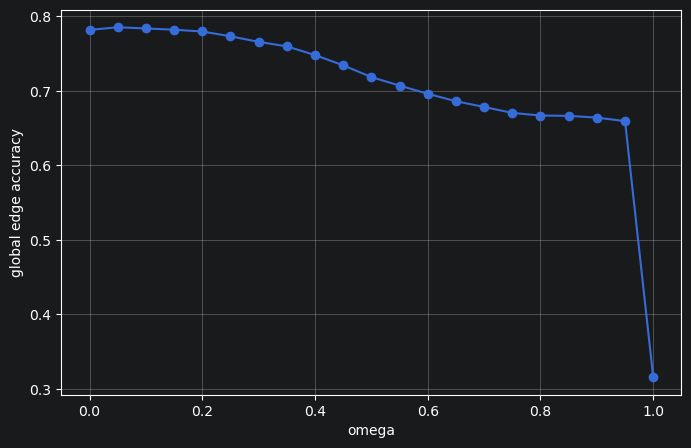

In [38]:
#grafico
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.plot(
    results["omega"],
    results["edge_accuracy"],
    marker="o"
)

plt.xlabel("omega")
plt.ylabel("global edge accuracy")
plt.grid(True)

plt.show()

### dal grafico e dai risultati vedo che la migliore accuracy ce l'ho dando molto peso alla matrice delle probabilità di transizione e poco alle distanze euclidee

In [39]:
## ottimizzazione con grid search per kendall tau
from scipy.stats import kendalltau

omegas = np.arange(0, 1.01, 0.05)

results_tau = []

for omega in omegas:

    C = (
        omega * D +
        (1 - omega) * (1 - P)
    )

    np.fill_diagonal(C.values, 0)

    taus = []

    for route_id in zone_sequences_reduced["route_id"].unique():

        actual = (
            zone_sequences_reduced
            .query("route_id == @route_id")
            .sort_values("zone_sequence_reduced")
            ["zone_id"]
            .tolist()
        )

        if len(actual) < 3:
            continue

        route_zones = list(dict.fromkeys(actual))

        C_route = C.loc[
            route_zones,
            route_zones
        ]

        pred = solve_otsp_greedy(
            C_route,
            actual[0]
        )

        actual_rank = {
            z: i for i, z in enumerate(actual)
        }

        pred_rank = {
            z: i for i, z in enumerate(pred)
        }

        common = [
            z for z in actual
            if z in pred_rank
        ]

        a = [actual_rank[z] for z in common]
        b = [pred_rank[z] for z in common]

        tau, _ = kendalltau(a, b)

        if not np.isnan(tau):
            taus.append(tau)

    results_tau.append({
        "omega": omega,
        "kendall_tau": np.mean(taus)
    })

results_tau = pd.DataFrame(results_tau)

best_tau = results_tau.loc[
    results_tau["kendall_tau"].idxmax()
]

print(results_tau)
print()
print("Best omega:", best_tau["omega"])
print("Best tau:", best_tau["kendall_tau"])

    omega  kendall_tau
0    0.00     0.714678
1    0.05     0.715292
2    0.10     0.713784
3    0.15     0.710993
4    0.20     0.706477
5    0.25     0.697343
6    0.30     0.688759
7    0.35     0.679907
8    0.40     0.665695
9    0.45     0.646361
10   0.50     0.622457
11   0.55     0.605890
12   0.60     0.592994
13   0.65     0.577635
14   0.70     0.567471
15   0.75     0.551730
16   0.80     0.550008
17   0.85     0.548222
18   0.90     0.545829
19   0.95     0.539002
20   1.00     0.337132

Best omega: 0.05
Best tau: 0.715292026159224


### su T

In [43]:
#per T
omegas = np.arange(0, 1.01, 0.05)

results = []

for omega in omegas:

    C = (
        omega * T +
        (1 - omega) * (1 - P)
    )

    np.fill_diagonal(C.values, 0)

    all_correct_edges = 0
    all_actual_edges = 0

    for route_id in zone_sequences_reduced["route_id"].unique():

        actual = (
            zone_sequences_reduced
            .query("route_id == @route_id")
            .sort_values("zone_sequence_reduced")
            ["zone_id"]
            .tolist()
        )

        if len(actual) < 2:
            continue

        route_zones = list(dict.fromkeys(actual))

        C_route = C.loc[
            route_zones,
            route_zones
        ]

        pred = solve_otsp_greedy(
            C_route,
            actual[0]
        )

        actual_edges = set(
            zip(actual[:-1], actual[1:])
        )

        pred_edges = set(
            zip(pred[:-1], pred[1:])
        )

        all_correct_edges += len(
            actual_edges & pred_edges
        )

        all_actual_edges += len(
            actual_edges
        )

    edge_acc = (
        all_correct_edges /
        all_actual_edges
    )

    results.append({
        "omega": omega,
        "edge_accuracy": edge_acc
    })

results = pd.DataFrame(results)

best = results.loc[
    results["edge_accuracy"].idxmax()
]

print(results)
print()
print("Best omega:", best["omega"])
print("Best edge accuracy:", best["edge_accuracy"])

    omega  edge_accuracy
0    0.00       0.781667
1    0.05       0.781764
2    0.10       0.781822
3    0.15       0.781822
4    0.20       0.781822
5    0.25       0.781822
6    0.30       0.781822
7    0.35       0.781822
8    0.40       0.781939
9    0.45       0.781881
10   0.50       0.781764
11   0.55       0.781725
12   0.60       0.781687
13   0.65       0.781493
14   0.70       0.781551
15   0.75       0.781551
16   0.80       0.781551
17   0.85       0.781144
18   0.90       0.778954
19   0.95       0.778062
20   1.00       0.066310

Best omega: 0.4
Best edge accuracy: 0.7819387102401582


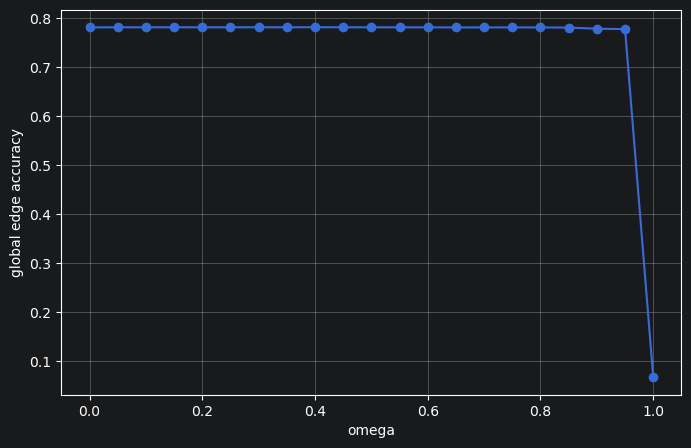

In [44]:
#grafico
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.plot(
    results["omega"],
    results["edge_accuracy"],
    marker="o"
)

plt.xlabel("omega")
plt.ylabel("global edge accuracy")
plt.grid(True)

plt.show()